# 1. Project Title and Student Identity

* **Judul Proyek:** Klasifikasi Ancaman Serangan DDoS pada Lalu Lintas Jaringan Menggunakan Decision Tree dan Random Forest
* **Nama:** Leo Agung Christian
* **NIM:** 2411501212
* **Tema Proyek:** Tema 2 Security Log Analytics and Threat Classification

# 2. Problem Identification and Security Context
* **Permasalahan Keamanan Siber:** naiknya volume lalu lintas jaringan membuat sistem deteksi susah belajar pola yang akurat jadi banyak sistem gagal mendeteksi serangan
* **Urgensi:** Serangan jaringan seperti Distributed Denial of Service (DDoS) dapat melumpuhkan layanan sistem dalam hitungan menit, menyebabkan kerugian finansial dan hilangnya kepercayaan pengguna.
* **Jenis Ancaman yang Dideteksi:** Serangan DDoS dibandingkan dengan aktivitas jaringan normal (BENIGN).
* **Peran AI/ML:** Machine Learning (Decision Tree dan Random Forest) mampu mempelajari pola statistik dari flow lalu lintas jaringan untuk mengklasifikasikan trafik berbahaya secara otomatis.
* **Kaitan dengan CIA Triad:**
  * **Availability:** DDoS secara langsung menyerang ketersediaan layanan dengan membanjiri bandwidth atau sumber daya server hingga pengguna sah tidak dapat mengakses sistem.
  * **Integrity & Confidentiality:** Saat tim keamanan sibuk menangani banjir trafik DDoS, penyerang sering memanfaatkan celah pengawasan untuk menyusup, mencuri data (Confidentiality), atau memodifikasi sistem (Integrity)

# 3. Dataset Collection and Description

Dataset yang digunakan berasal dari **CIC-IDS2017**.

**Karakteristik Dataset:**
* Berisi catatan network flow hasil ekstraksi trafik jaringan menggunakan CICFlowMeter.
* Terdiri dari 225.745 baris data dan 79 kolom
* Memiliki dua kelas target: DDoS (serangan) dan BENIGN (trafik normal).

In [ ]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_files = glob.glob('/content/sample_data/*DDos*.csv') + glob.glob('/content/*DDos*.csv')
if not csv_files:
    raise FileNotFoundError("File CSV tidak ditemukan di /content/sample_data/ atau /content/.")
file_path = csv_files[0]
print(f"Dataset dimuat dari: {file_path}")
df = pd.read_csv(file_path)

# Merapikan spasi berlebih pada nama kolom
df.columns = df.columns.str.strip()
print(f"Jumlah baris & kolom awal: {df.shape}")
print("\nRingkasan Tipe Data Kolom:")
print(df.dtypes.value_counts())
print("\nDistribusi Kelas Awal:")
print(df['Label'].value_counts())
print("\n5 Baris Pertama Dataset:")
display(df.head())

Dataset dimuat dari: /content/sample_data/Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
Jumlah baris & kolom awal: (225745, 79)

Ringkasan Tipe Data Kolom:
int64      54
float64    24
object      1
Name: count, dtype: int64

Distribusi Kelas Awal:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

5 Baris Pertama Dataset:


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,54865,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
1,55054,109,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
2,55055,52,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
3,46236,34,1,1,6,6,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN
4,54863,3,2,0,12,0,6,6,6.0,0.0,...,20,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN


# 4. Data Cleaning and Preprocessing

1. Konversi nilai tak hingga (`inf` / `-inf`) menjadi `NaN` karena dapat menyebabkan*error saat scaling dan pelatihan model.
2. Identifikasi dan penghapusan missing values.
3. Identifikasi dan penghapusan baris data duplikat agar tidak memicu bias evaluasi.

In [ ]:
# Ganti nilai infinity menjadi NaN
df.replace([np.inf, -np.inf], np.nan, inplace=True)
missing_count = df.isnull().sum().sum()
duplicate_count = df.duplicated().sum()
print(f"Jumlah Missing Values (termasuk inf): {missing_count}")
print(f"Jumlah Data Duplikat                : {duplicate_count}")

# Hapus missing values dan duplikat
df_clean = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"\nJumlah baris & kolom setelah cleaning: {df_clean.shape}")
print("\nDistribusi Kelas Setelah Cleaning:")
print(df_clean['Label'].value_counts())
print("\nProporsi Kelas (%):")
print((df_clean['Label'].value_counts(normalize=True) * 100).round(2))

Jumlah Missing Values (termasuk inf): 68
Jumlah Data Duplikat                : 2633

Jumlah baris & kolom setelah cleaning: (223082, 79)

Distribusi Kelas Setelah Cleaning:
Label
DDoS      128014
BENIGN     95068
Name: count, dtype: int64

Proporsi Kelas (%):
Label
DDoS      57.38
BENIGN    42.62
Name: proportion, dtype: float64


**Interpretasi Data Cleaning:**
Dari 225.745 baris awal, ditemukan 68 missing values dan 2.633 baris duplikat. Setelah dibersihkan, tersisa 223.082 baris data bersih dengan 79 kolom, terdiri dari DDoS sebesar 57,38% (128.014 baris) dan BENIGN sebesar 42,62% (95.068 baris).

# 5. Exploratory Data Analysis (EDA)

Analisis eksplorasi dilakukan untuk memahami karakteristik statistik data, keseimbangan kelas, korelasi antarfitur, serta pola pembeda antara trafik normal (BENIGN) dan serangan DDoS.

Statistik Deskriptif (10 Fitur Pertama):


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std
count,223082.000000,2.230820e+05,223082.000000,223082.000000,223082.000000,2.230820e+05,223082.000000,223082.000000,223082.000000,223082.000000
mean,8979.381089,1.643543e+07,4.905806,4.612134,949.789548,6.030165e+03,544.648017,27.904941,166.481071,217.468255
std,19844.769163,3.166173e+07,15.510750,21.881574,3267.282558,3.944650e+04,1874.374045,164.253645,507.655519,801.809745
min,0.000000,-1.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000
25%,80.000000,8.179200e+04,2.000000,1.000000,26.000000,0.000000e+00,6.000000,0.000000,6.000000,0.000000
50%,80.000000,1.537870e+06,3.000000,4.000000,30.000000,1.640000e+02,20.000000,0.000000,8.666667,5.301991
75%,80.000000,8.958819e+06,5.000000,5.000000,62.000000,1.160100e+04,35.000000,6.000000,32.000000,10.263203
max,65532.000000,1.199999e+08,1932.000000,2942.000000,183012.000000,5.172346e+06,11680.000000,1472.000000,3867.000000,6692.644993


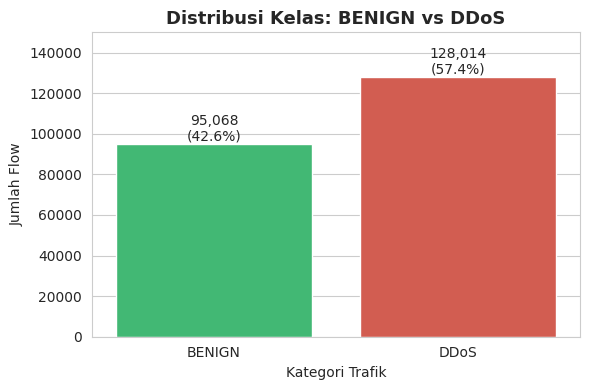

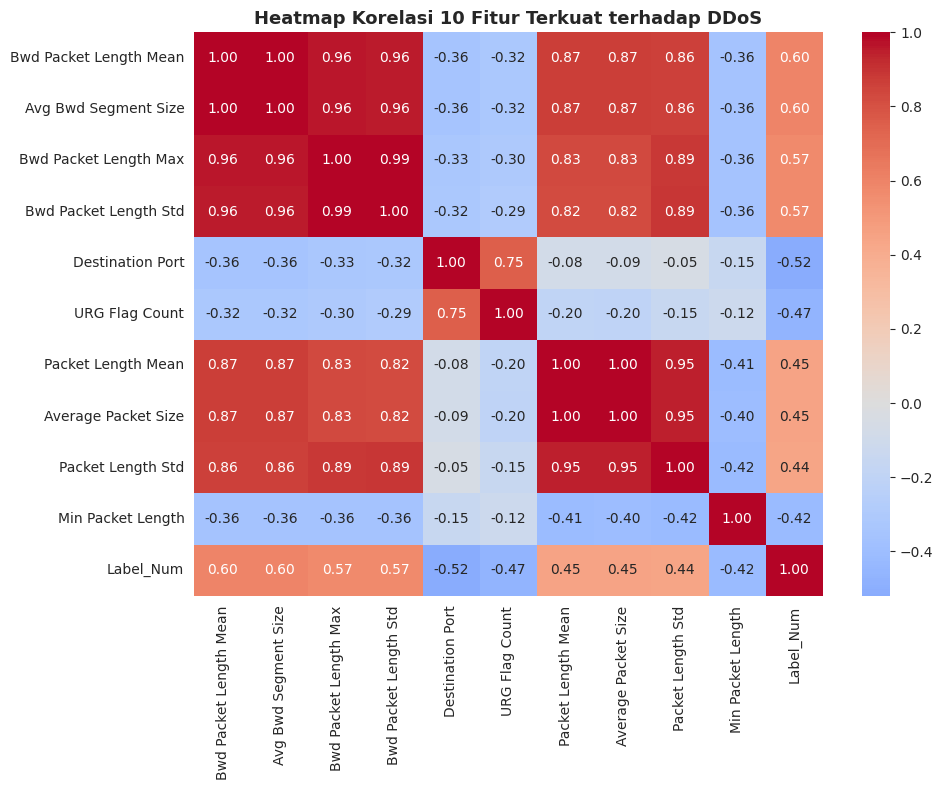

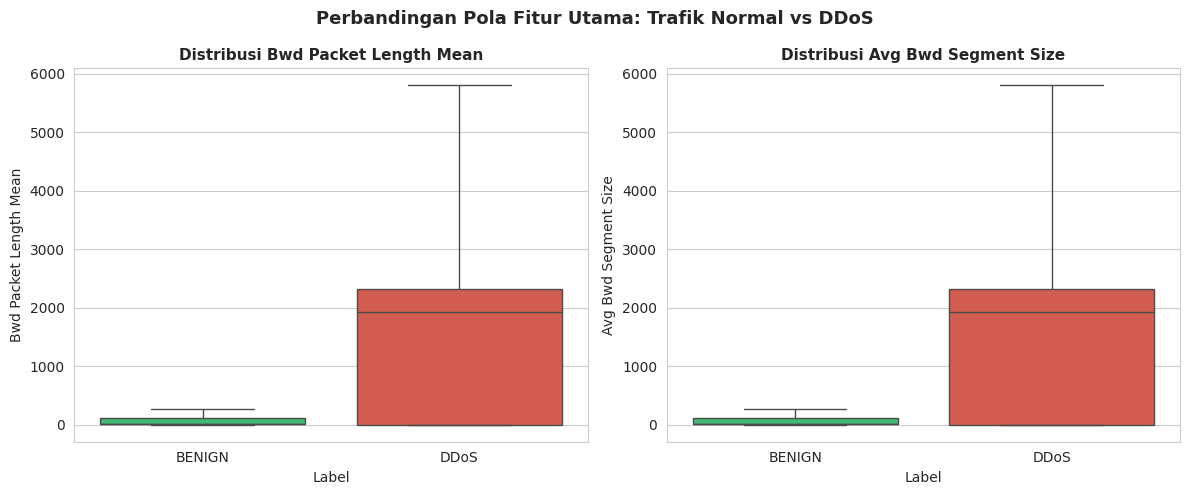


10 Fitur dengan Korelasi Absolut Tertinggi terhadap DDoS:
Bwd Packet Length Mean    0.599916
Avg Bwd Segment Size      0.599916
Bwd Packet Length Max     0.573809
Bwd Packet Length Std     0.572738
Destination Port          0.520315
URG Flag Count            0.472218
Packet Length Mean        0.448248
Average Packet Size       0.447548
Packet Length Std         0.437650
Min Packet Length         0.422728
Name: Label_Num, dtype: float64


In [5]:
import warnings
warnings.filterwarnings('ignore')
# Statistik Deskriptif
print("Statistik Deskriptif (10 Fitur Pertama):")
display(df_clean.iloc[:, :10].describe())

# Salinan sementara untuk menghitung korelasi
df_eda = df_clean.copy()
df_eda['Label_Num'] = df_eda['Label'].map({'BENIGN': 0, 'DDoS': 1})

# Ambil 10 fitur dengan korelasi absolut tertinggi terhadap DDoS
corr_target = df_eda.drop(columns=['Label']).corr()['Label_Num'].abs().sort_values(ascending=False)
top_features = corr_target.index[1:11].tolist()
sns.set_style("whitegrid")

# Visualisasi Distribusi Kelas
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Label', data=df_clean, palette=['#2ecc71', '#e74c3c'])
plt.title('Distribusi Kelas: BENIGN vs DDoS', fontsize=13, fontweight='bold')
plt.xlabel('Kategori Trafik')
plt.ylabel('Jumlah Flow')
for p in ax.patches:
    pct = f"{100 * p.get_height() / len(df_clean):.1f}%"
    ax.annotate(f'{int(p.get_height()):,}\n({pct})', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=10)
plt.ylim(0, 150000)
plt.tight_layout()
plt.show()

# Visualisasi Heatmap Korelasi 10 Fitur
plt.figure(figsize=(10, 8))
corr_matrix = df_eda[top_features + ['Label_Num']].corr()
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi 10 Fitur Terkuat terhadap DDoS', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Visualisasi Perbandingan Distribusi 2 Fitur Utama
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, feat in enumerate(top_features[:2]):
    sns.boxplot(x='Label', y=feat, data=df_clean, ax=axes[i],
                palette=['#2ecc71', '#e74c3c'], showfliers=False)
    axes[i].set_title(f'Distribusi {feat}', fontsize=11, fontweight='bold')
plt.suptitle('Perbandingan Pola Fitur Utama: Trafik Normal vs DDoS', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
print("\n10 Fitur dengan Korelasi Absolut Tertinggi terhadap DDoS:")
print(corr_target.iloc[1:11])

**Interpretasi EDA:**
* **Distribusi Kelas:** Proporsi kelas DDoS (57,4%) dan BENIGN (42,6%) udah seimbang.
* **Korelasi Fitur:** Fitur yang paling kuat berkorelasi positif dengan DDoS adalah karakteristik ukuran paket balik (Bwd Packet Length Mean dan Avg Bwd Segment Size sebesar 0,60, Bwd Packet Length Max sebesar 0,57). Sementara itu, Destination Port berkorelasi negatif (-0,52), yang menunjukkan pola serangan DDoS terkonsentrasi pada port layanan bernomor kecil seperti port 80 (HTTP).


# 6. Feature Engineering

1. **Feature Labeling / Encoding:** Mengubah label kategorikal (BENIGN -> 0, DDoS -> 1) agar dapat diproses algoritma Machine Learning.
2. **Feature Selection:** Membuang kolom bernilai konstan (variansi nol) karena tidak memberi informasi pembeda, lalu memilih 20 fitur dengan korelasi absolut tertinggi terhadap target untuk mengurangi dimensi, mempercepat pelatihan, dan menekan risiko *overfitting*.
3. **Train-Test Split & Feature Scaling:** Membagi data secara stratified (80% training, 20% testing) lalu menerapkan StandardScaler (fit hanya pada data training untuk mencegah data leakage).

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Label Encoding
df_fe = df_clean.copy()
df_fe['Label'] = df_fe['Label'].map({'BENIGN': 0, 'DDoS': 1})
X = df_fe.drop(columns=['Label'])
y = df_fe['Label']

# Feature Selection
constant_cols = [col for col in X.columns if X[col].nunique() <= 1]
X = X.drop(columns=constant_cols)
print(f"Kolom konstan yang dibuang: {len(constant_cols)}")

# 20 fitur dengan korelasi absolut tertinggi terhadap Label
corr_target_fe = X.corrwith(y).abs().sort_values(ascending=False)
selected_features = corr_target_fe.head(20).index.tolist()
X_selected = X[selected_features]
print(f"Jumlah fitur akhir yang dipakai: {len(selected_features)}")
print("\nDaftar 20 Fitur Terpilih:")
for i, feat in enumerate(selected_features, 1):
    print(f"{i:2d}. {feat} ({corr_target_fe[feat]:.4f})")

# Split Data Training (80%) dan Testing (20%
X_train, X_test, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
print(f"\nUkuran Data Training: {X_train_scaled.shape}")
print(f"Ukuran Data Testing : {X_test_scaled.shape}")

Kolom konstan yang dibuang: 10
Jumlah fitur akhir yang dipakai: 20

Daftar 20 Fitur Terpilih:
 1. Bwd Packet Length Mean (0.5999)
 2. Avg Bwd Segment Size (0.5999)
 3. Bwd Packet Length Max (0.5738)
 4. Bwd Packet Length Std (0.5727)
 5. Destination Port (0.5203)
 6. URG Flag Count (0.4722)
 7. Packet Length Mean (0.4482)
 8. Average Packet Size (0.4475)
 9. Packet Length Std (0.4377)
10. Min Packet Length (0.4227)
11. Max Packet Length (0.4080)
12. min_seg_size_forward (0.4061)
13. Packet Length Variance (0.4032)
14. Fwd Packet Length Mean (0.3636)
15. Avg Fwd Segment Size (0.3636)
16. Bwd Packet Length Min (0.3628)
17. Fwd Packet Length Max (0.3280)
18. Subflow Fwd Bytes (0.3260)
19. Total Length of Fwd Packets (0.3260)
20. Bwd IAT Total (0.3254)

Ukuran Data Training: (178465, 20)
Ukuran Data Testing : (44617, 20)


**Interpretasi Feature Engineering:**
Dari 78 fitur awal, 10 kolom konstan berhasil dibuang. Sebanyak 20 fitur paling relevan, dipilih agar model fokus pada sinyal serangan DDoS. Data dibagi menjadi 178.465 baris training dan 44.617 baris testing dengan skala fitur yang seragam.

# 7. Machine Learning Model Development

1. **Decision Tree Classifier:** Memisahkan data secara hierarkis berdasarkan fitur paling informatif.
   * max_depth=10: Membatasi kedalaman pohon agar tidak overfitting.
   * random_state=4: Menjamin hasil pelatihan konsisten.
2. **Random Forest Classifier:** Model ensemble yang menggabungkan banyak pohon keputusan untuk meningkatkan stabilitas dan akurasi prediksi.
   * n_estimators=100: Menggunakan 100 pohon keputusan.
   * max_depth=10: Menjaga efisiensi komputasi dan mencegah overfitting.
   * random_state=42: Menjamin reproduktibilitas hasil eksperimen.

In [7]:
import time
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

# Training Decision Tree
start_dt = time.time()
dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train_scaled, y_train)
dt_train_time = time.time() - start_dt
y_pred_dt = dt_model.predict(X_test_scaled)

# Training Random Forest
start_rf = time.time()
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42, n_jobs=2)
rf_model.fit(X_train_scaled, y_train)
rf_train_time = time.time() - start_rf
y_pred_rf = rf_model.predict(X_test_scaled)
print(f"Decision Tree selesai dilatih dalam {dt_train_time:.2f} detik.")
print(f"Random Forest selesai dilatih dalam {rf_train_time:.2f} detik.")

Decision Tree selesai dilatih dalam 0.64 detik.
Random Forest selesai dilatih dalam 13.18 detik.


# 8. Model Evaluation and Comparison


,Model,Accuracy,Precision,Recall,F1-Score,False Positive (FP),False Negative (FN),Train Time (s)
0,Decision Tree,0.999552,0.999844,0.999375,0.999609,4,16,0.64
1,Random Forest,0.999574,0.999883,0.999375,0.999629,3,16,13.18



Classification Report: Decision Tree
              precision    recall  f1-score   support

      BENIGN     0.9992    0.9998    0.9995     19014
        DDoS     0.9998    0.9994    0.9996     25603

    accuracy                         0.9996     44617
   macro avg     0.9995    0.9996    0.9995     44617
weighted avg     0.9996    0.9996    0.9996     44617

Classification Report: Random Forest
              precision    recall  f1-score   support

      BENIGN     0.9992    0.9998    0.9995     19014
        DDoS     0.9999    0.9994    0.9996     25603

    accuracy                         0.9996     44617
   macro avg     0.9995    0.9996    0.9996     44617
weighted avg     0.9996    0.9996    0.9996     44617



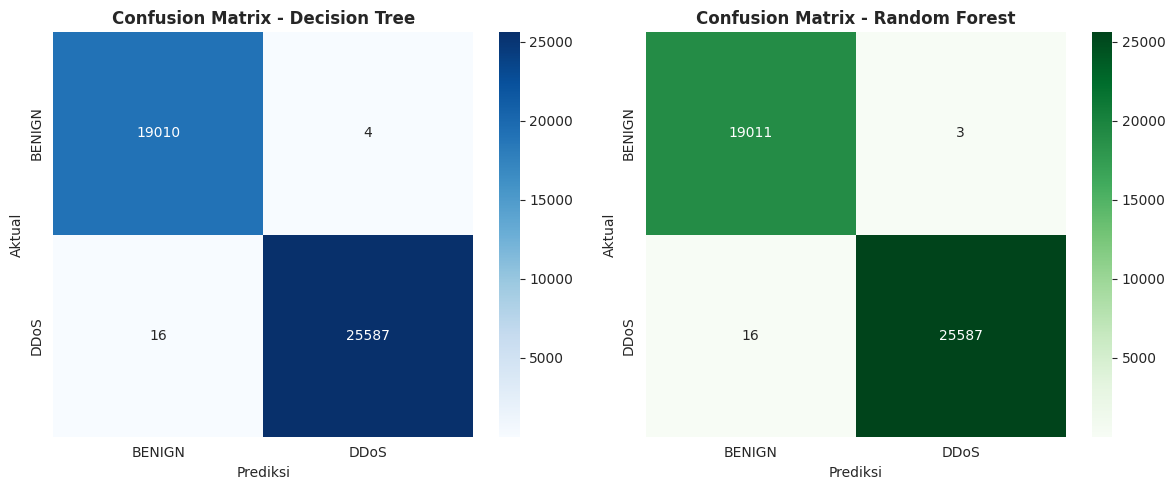

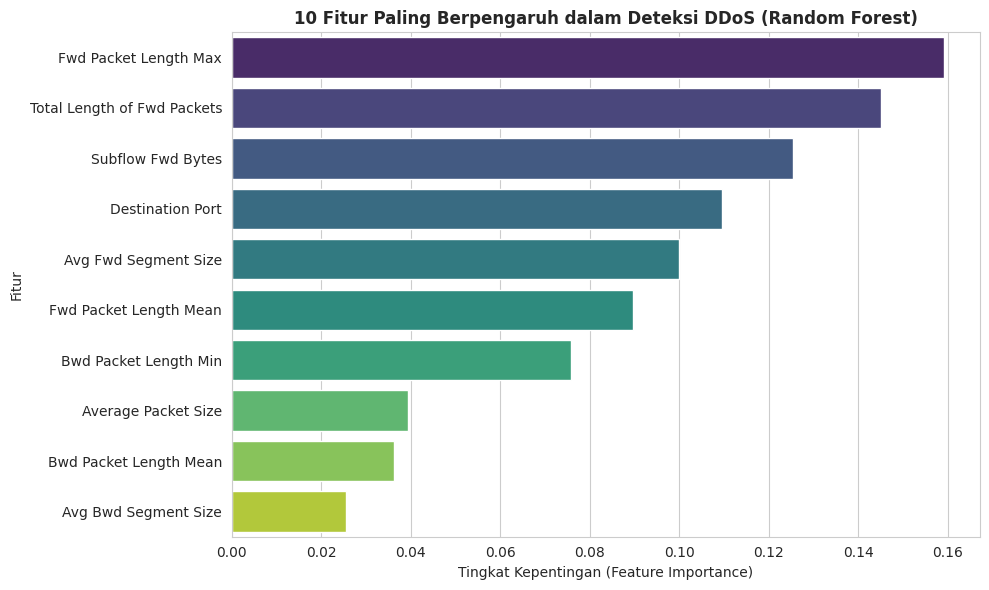

In [8]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report
)

def evaluate_model(name, y_true, y_pred, train_time):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    return {
        'Model': name,
        'Accuracy': round(accuracy_score(y_true, y_pred), 6),
        'Precision': round(precision_score(y_true, y_pred), 6),
        'Recall': round(recall_score(y_true, y_pred), 6),
        'F1-Score': round(f1_score(y_true, y_pred), 6),
        'False Positive (FP)': int(fp),
        'False Negative (FN)': int(fn),
        'Train Time (s)': round(train_time, 2)
    }

# Tabel Perbandingan Performa Model
results_df = pd.DataFrame([
    evaluate_model('Decision Tree', y_test, y_pred_dt, dt_train_time),
    evaluate_model('Random Forest', y_test, y_pred_rf, rf_train_time)
])
display(results_df)
print("\nClassification Report: Decision Tree")
print(classification_report(y_test, y_pred_dt, target_names=['BENIGN', 'DDoS'], digits=4))
print("Classification Report: Random Forest")
print(classification_report(y_test, y_pred_rf, target_names=['BENIGN', 'DDoS'], digits=4))

# Visualisasi Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['BENIGN', 'DDoS'], yticklabels=['BENIGN', 'DDoS'])
axes[0].set_title('Confusion Matrix - Decision Tree', fontweight='bold')
axes[0].set_xlabel('Prediksi')
axes[0].set_ylabel('Aktual')
cm_rf = confusion_matrix(y_test, y_pred_rf)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['BENIGN', 'DDoS'], yticklabels=['BENIGN', 'DDoS'])
axes[1].set_title('Confusion Matrix - Random Forest', fontweight='bold')
axes[1].set_xlabel('Prediksi')
axes[1].set_ylabel('Aktual')
plt.tight_layout()
plt.show()

# Visualisasi 10 Fitur Paling Berpengaruh pada Random Forest
importances = pd.Series(rf_model.feature_importances_, index=selected_features).sort_values(ascending=False)
plt.figure(figsize=(10, 6))
sns.barplot(x=importances.head(10), y=importances.head(10).index, palette='viridis')
plt.title('10 Fitur Paling Berpengaruh dalam Deteksi DDoS (Random Forest)', fontweight='bold')
plt.xlabel('Tingkat Kepentingan (Feature Importance)')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

# 9. Security Analysis and Discussion

1. **Apakah model mampu mengidentifikasi aktivitas malicious?**  
   Ya. Baik Decision Tree maupun Random Forest mampu membedakan trafik DDoS dan BENIGN dengan sangat akurat, ditunjukkan oleh nilai Accuracy dan F1-Score di atas 99,95%* pada 44.617 data uji. Dari total 25.603 aliran DDoS pada data testing, kedua model berhasil mendeteksi 25.587 aliran DDoS dengan tepat.

2. **Apa perbedaan performa dari algoritma yang digunakan?**  
   * **Random Forest** sedikit lebih unggul pada metrik akurasi (99,9574% dibandingkan 99,9552%), Precision (99,9883% dibandingkan 99,9844%), dan F1-Score (99,9629% dibandingkan 99,9609%), dengan jumlah False Positive yang lebih rendah (3 kasus dibandingkan 4 kasus) serta jumlah False Negative yang sama (16 kasus). Sifat ensemble dari 100 pohon membuatnya lebih stabil terhadap variasi data.
   * **Decision Tree**Decision Tree unggul jauh pada kecepatan pelatihan (di bawah 1 detik, jauh lebih cepat dibandingkan Random Forest yang memakan waktu lebih lama karena membangun 100 pohon), sehingga sangat ringan secara komputasi meskipun hanya mengandalkan satu pohon keputusan.

3. **Apa konsekuensi False Positive dan False Negative dalam Cyber Security?**  
   * **False Positive (Trafik BENIGN diklasifikasikan sebagai DDoS):** Menyebabkan pemblokiran akses pengguna sah dan menimbulkan alert fatigue bagi analis SOC akibat terlalu banyak peringatan palsu. Pada eksperimen ini, Random Forest hanya menghasilkan 3 False Positive dari 19.014 trafik normal.
   * **False Negative (Serangan DDoS lolos sebagai BENIGN):** Memiliki risiko paling fatal karena serangan berhasil menembus pertahanan, membanjiri sumber daya server, dan melumpuhkan Availability layanan. Meskipun hanya 16 dari 25.603 aliran DDoS yang lolos (Recall 99,9375%), dalam skenario nyata nilai Recall harus terus dioptimalkan.

4. **Apakah model dapat digunakan dalam lingkungan keamanan jaringan nyata?**  
   Model ini potensial digunakan sebagai mesin deteksi pendukung pada Intrusion Detection System (IDS) atau SIEM. Namun, untuk penerapan di lingkungan produksi (real-time), model perlu diintegrasikan dengan pipeline ekstraksi fitur streaming serta diuji terlebih dahulu pada trafik jaringan aktual agar tahan terhadap perubahan pola trafik (concept drift).

5. **Apa keterbatasan model yang dikembangkan?**  
   * Dataset CIC-IDS2017 berasal dari lingkungan simulasi laboratorium tahun 2017 sehingga mungkin kurang representatif terhadap teknik DDoS modern (zero-day atau low-and-slow DDoS).
   * Klasifikasi masih bersifat biner (membedakan antara kelas BENIGN dan DDoS), sehingga belum mencakup multi-kelas serangan lain seperti PortScan, Brute Force, atau Botnet.
   * Fitur yang digunakan berbasis network flow (dihitung setelah sesi aliran berakhir), sehingga memiliki potensi jeda deteksi (latency) jika diterapkan langsung pada trafik real-time.

# 10. Conclusion and Future Recommendation

* **Ringkasan Proses dan Hasil Eksperimen:** Proyek ini mengimplementasikan pipeline klasifikasi ancaman DDoS pada dataset CIC-IDS2017 (`Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv`). Dari 225.745 baris awal, pembersihan data menghasilkan 223.082 baris bersih. Setelah dilakukan EDA dan Feature Engineering (pembuangan 10 fitur konstan, seleksi 20 fitur terkuat, stratified split 80:20, dan StandardScaler), model Decision Tree dan Random Forest berhasil dilatih dan dievaluasi.
* **Algoritma Terbaik:** Berdasarkan perbandingan metrik evaluasi, **Random Forest** merupakan algoritma terbaik karena menawarkan Accuracy (99,9574%), Precision (99,9883%), Recall (99,9375%), dan F1-Score (99,9629%) tertinggi dengan jumlah kesalahan klasifikasi paling minimal (3 FP dan 16 FN).
* **Potensi Implementasi:** Model dapat diintegrasikan ke dalam sistem pemantauan jaringan (IDS/SIEM/NGFW) sebagai lapisan deteksi otomatis untuk mempercepat respons mitigasi DDoS di Security Operations Center (SOC).
* **Keterbatasan Penelitian:** Eksperimen masih terbatas pada data historis offline (2017) dengan klasifikasi dua kelas (biner).
* **Rekomendasi Pengembangan Selanjutnya:**
  1. Memperluas eksperimen menggunakan dataset yang lebih mutakhir (misalnya **CIC-DDoS2019**) dan melakukan klasifikasi multi-class.
  2. Menerapkan K-Fold Cross Validation dan hyperparameter tuning (GridSearchCV / RandomizedSearchCV) untuk menguji ketahanan generalisasi model.
  3. Membandingkan dengan algoritma gradient boosting (XGBoost/LightGBM) serta mengukur inference latency untuk skenario deteksi real-time.

# 11. References

1. Sharafaldin, I., Lashkari, A. H., & Ghorbani, A. A. (2018). *Toward Generating a New Intrusion Detection Dataset and Intrusion Traffic Characterization*. Proceedings of the 4th International Conference on Information Systems Security and Privacy (ICISSP), 108–116.
2. Canadian Institute for Cybersecurity (CIC). *Intrusion Detection Evaluation Dataset (CIC-IDS2017)*. University of New Brunswick. https://www.unb.ca/cic/datasets/ids-2017.html
3. Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., ... & Duchesnay, E. (2011). *Scikit-learn: Machine Learning in Python*. Journal of Machine Learning Research, 12, 2825–2830.